In [ ]:

import pandas as pd
import numpy as np

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name, encoding="utf-8", encoding_errors="replace")

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()


Saving IMDb Movies India.csv to IMDb Movies India (1).csv
Dataset loaded successfully!
Dataset shape: (15509, 10)

Columns:
['Name', 'Year', 'Duration', 'Genre', 'Rating', 'Votes', 'Director', 'Actor 1', 'Actor 2', 'Actor 3']


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


In [ ]:

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Available columns:", df.columns.tolist())

if "rating" not in df.columns:
    raise ValueError(
        "Rating column nahi mila. Dataset ke column names check karein."
    )

df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

df = df.dropna(subset=["rating"]).copy()

feature_columns = [
    col for col in [
        "genre", "director", "actor_1", "actor_2",
        "actor_3", "name", "year", "duration"
    ]
    if col in df.columns
]

if not feature_columns:
    raise ValueError(
        "Genre, Director, Actors ya Name jaise feature columns nahi mile."
    )

df["movie_features"] = (
    df[feature_columns]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

df = df[df["movie_features"] != ""].copy()

print("Features used:", feature_columns)
print("Cleaned dataset shape:", df.shape)
df[feature_columns + ["rating"]].head()


Available columns: ['name', 'year', 'duration', 'genre', 'rating', 'votes', 'director', 'actor_1', 'actor_2', 'actor_3']
Features used: ['genre', 'director', 'actor_1', 'actor_2', 'actor_3', 'name', 'year', 'duration']
Cleaned dataset shape: (7919, 11)


,genre,director,actor_1,actor_2,actor_3,name,year,duration,rating
1,Drama,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid,#Gadhvi (He thought he was Gandhi),(2019),109 min,7.0
3,"Comedy, Romance",Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor,#Yaaram,(2019),110 min,4.4
5,"Comedy, Drama, Musical",Rahul Rawail,Bobby Deol,Aishwarya Rai Bachchan,Shammi Kapoor,...Aur Pyaar Ho Gaya,(1997),147 min,4.7
6,"Drama, Romance, War",Shoojit Sircar,Jimmy Sheirgill,Minissha Lamba,Yashpal Sharma,...Yahaan,(2005),142 min,7.4
8,"Horror, Mystery, Thriller",Allyson Patel,Yash Dave,Muntazir Ahmad,Kiran Bhatia,?: A Question Mark,(2012),82 min,5.6


In [ ]:

X = df["movie_features"]
y = df["rating"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 6335
Testing samples: 1584


In [ ]:

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        stop_words="english"
    )),
    ("regressor", Ridge(alpha=1.0))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [ ]:

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"R² Score: {r2:.3f}")


Mean Absolute Error (MAE): 0.875
Root Mean Squared Error (RMSE): 1.124
R² Score: 0.320


In [ ]:

new_movie = {
    "genre": "Action Drama",
    "director": "Example Director",
    "actor_1": "Example Actor",
    "actor_2": "Another Actor",
    "actor_3": "",
    "name": "Example Movie",
    "year": "2026",
    "duration": "120 min"
}

movie_text = " ".join(
    str(new_movie.get(col, "") or "")
    for col in feature_columns
)

predicted_rating = model.predict([movie_text])[0]

print(f"Predicted Movie Rating: {predicted_rating:.2f}")


Predicted Movie Rating: 5.77


In [ ]:

comparison = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": y_pred
})

comparison["Predicted Rating"] = comparison["Predicted Rating"].round(2)

comparison.head(10)


,Actual Rating,Predicted Rating
0,3.3,4.57
1,5.3,6.65
2,5.7,5.55
3,7.2,5.62
4,3.5,3.70
5,7.2,5.30
6,3.8,6.74
7,6.9,4.84
8,5.2,5.82
9,7.4,6.57


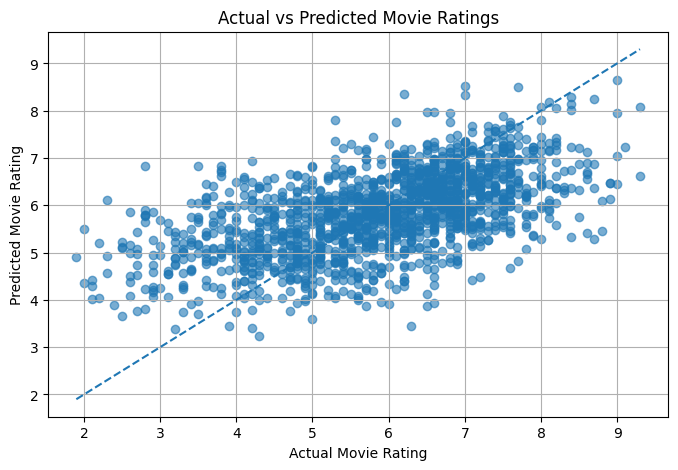

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6)

# Ideal prediction line
min_rating = min(y_test.min(), y_pred.min())
max_rating = max(y_test.max(), y_pred.max())

plt.plot(
    [min_rating, max_rating],
    [min_rating, max_rating],
    linestyle="--"
)

plt.xlabel("Actual Movie Rating")
plt.ylabel("Predicted Movie Rating")
plt.title("Actual vs Predicted Movie Ratings")
plt.grid(True)
plt.show()


In [ ]:

import joblib

joblib.dump(model, "movie_rating_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [ ]:
print("Average actual rating:", round(y.mean(), 2))
print("Average predicted rating:", round(y_pred.mean(), 2))
print("Model MAE:", round(mae, 2))

Average actual rating: 5.84
Average predicted rating: 5.84
Model MAE: 0.88


In [ ]:
TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 1),
    stop_words="english"
)

TfidfVectorizer(max_features=30000, stop_words='english')

In [ ]:
print("Dataset rows:", len(df))
print("Dataset columns:", len(df.columns))

Dataset rows: 7919
Dataset columns: 11


In [ ]:

from google.colab import files

files.download("movie_rating_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>